# IMPORT

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import folium
import csv
import json
import os

# DEFINE FOLDERS

In [9]:
JSON_INPUT_FOLDER = Path("../data/correlated_data_json")
DATASET_INPUT_FOLDER = Path("../data/correlated_data_csv")
DATASET_OUTPUT_FOLDER = Path("../data/clean_data_csv")
DELETED_STATIONS_FOLDER = Path("../data/deleted_stations")
MAP_FOLDER = Path("../data/maps")
COORDINATES_FOLDER = Path("../data/station_coordinates")

folders = [JSON_INPUT_FOLDER, DATASET_INPUT_FOLDER, DATASET_OUTPUT_FOLDER, DELETED_STATIONS_FOLDER, MAP_FOLDER, COORDINATES_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [10]:
REMAKE_CSV = False # To get the dataset from json files(will be saved in a csv file)
CSV_FILE_NAME = "correlated_data" #To save the dataset from json to csv/to get the dataset from csv
FINAL_CSV_FILE_NAME = "final_clean_split_data" # The prepared dataset

# DEFINE VARIABLES

In [11]:
# Not exactly variables as we will modify them only once at the start
TOTAL_ROWS_AT_START = 1 # 1 to avoid division by zero
TOTAL_REAL_ROWS_AT_START = 1
TOTAL_STATIONS_AT_START = 1
TOTAL_REAL_STATIONS_AT_START = 1

# Probably will not need those
TOTAL_DELETED_STATIONS = 0
TOTAL_DELETED_ROWS = 0

# DEFINE FUNCS

In [12]:
def print_df(dataframe):
    print("=========================================")
    print(f"Dataframe analysis")
    print("-----------------------")
    print(f"Shape: \nrows:     {dataframe.shape[0]}\nfeatures: {dataframe.shape[1]}")
    
    data_size_bytes = dataframe.memory_usage(deep=True).sum()
    data_size_mb = data_size_bytes / (1024**2)
    print(f"Dataframe size: {data_size_bytes} bytes ({data_size_mb:.2f} MB)")

    print("-----------------------")

    station_col = "station_code" if "station_code" in dataframe.columns else "stationcode"

    rows_pct = (TOTAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_ROWS_AT_START * 100
    stations_pct = (TOTAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_STATIONS_AT_START * 100
    real_rows_pct = (TOTAL_REAL_ROWS_AT_START - dataframe.shape[0]) / TOTAL_REAL_ROWS_AT_START * 100
    real_stations_pct = (TOTAL_REAL_STATIONS_AT_START - dataframe[station_col].nunique()) / TOTAL_REAL_STATIONS_AT_START * 100

    print(f"Percentage of rows removed: {rows_pct:.2f}%")
    print(f"Percentage of stations removed: {stations_pct:.2f}%")
    print(f"Percentage of real rows removed: {real_rows_pct:.2f}%")
    print(f"Percentage of real stations removed: {real_stations_pct:.2f}%")

    print("-----------------------")
    display(dataframe.dtypes)
    print("-----------------------")
    display(dataframe.describe())
    print("=========================================")

MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}
def rows_with_missing(df):
    # NaN anywhere
    mask = df.isna().any(axis=1)

    # Only object columns
    obj_df = df.select_dtypes(include="object")

    if not obj_df.empty:
        # Normalize all strings at once
        normalized = obj_df.apply(
            lambda col: col.str.strip().str.lower()
        )

        # Check missing-like strings (row-wise)
        string_missing = normalized.isin(MISSING_STRINGS).any(axis=1)

        mask |= string_missing

    return df[mask]

def print_missing(dataframe, max_rows=10):
    print("=========================================")
    print(f"Missing diagnostics")
    print("-----------------------")

    # NaN count per column
    nan_counts = dataframe.isna().sum().sort_values(ascending=False)

    # Inf count per numeric column
    numeric_df = dataframe.select_dtypes(include=[np.number])
    inf_counts = np.isinf(numeric_df).sum()

    problem_counts = (
        pd.DataFrame({
            "nan": nan_counts,
            "inf": inf_counts
        })
        .fillna(0)
        .astype(int)
        .sort_values(by=["nan", "inf"], ascending=False)
    )

    print("\nNaN / Inf per column:")
    display(problem_counts)

    print("-----------------------")

    # missing_rows = rows_with_missing(dataframe)
    # print(f"\nRows with missing-like values: {len(missing_rows)}")
    # display(missing_rows.head(max_rows))

    print("=========================================")



# IF WANT TO REMAKE CSV FILE FROM JSON FILES

In [13]:
CHUNK_SIZE = 50_000   # chunk size to save each time to CSV_FILE_NAME, so the memory doesn't explode
first_write = True

csv_path = os.path.join(DATASET_INPUT_FOLDER, f"{CSV_FILE_NAME}.csv")
total_file_num = len(os.listdir(JSON_INPUT_FOLDER))

if REMAKE_CSV:
    for file_idx, filename in enumerate(os.listdir(JSON_INPUT_FOLDER), start=1):
        if not filename.endswith(".json"):
            continue

        path = os.path.join(JSON_INPUT_FOLDER, filename)

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        rows = []

        for entry in data:
            row = {}

            # Station fields
            fields = entry.get("fields", {})
            for key, value in fields.items():
                if key == "coordonnees_geo" and isinstance(value, list) and len(value) == 2:
                    row["latitude"] = value[0]
                    row["longitude"] = value[1]
                else:
                    row[key] = value

            # Weather fields
            weather = entry.get("weather", {})
            if "time" in weather:
                row["weather_time"] = weather["time"]

            for key, value in weather.items():
                if key != "time":
                    row[f"weather_{key}"] = value

            row["source_file"] = filename
            rows.append(row)

            # Write chunk
            if len(rows) >= CHUNK_SIZE:
                df_chunk = pd.DataFrame(rows)
                df_chunk.to_csv(
                    csv_path,
                    mode="w" if first_write else "a",
                    header=first_write,
                    index=False,
                    encoding="utf-8"
                )
                first_write = False
                rows.clear()

        # Flush remaining rows of this file
        if rows:
            df_chunk = pd.DataFrame(rows)
            df_chunk.to_csv(
                csv_path,
                mode = "w" if first_write else "a",
                header = first_write,
                index = False,
                encoding="utf-8"
            )
            first_write = False

        if file_idx % 100 == 0:
            print(f"{file_idx}/{total_file_num} JSON files processed")

    print("CSV generation finished.")

# LOAD DATA

In [14]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")
df.head(5)

C:\Users\emirh\AppData\Local\Temp\ipykernel_134720\226569353.py:1: DtypeWarning: Columns (2,3,4,5,8,9,14,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")


,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111,2,0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2.0,22,25,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017,5,1,48.936269,2.358867,2025-11-04T03:21:03+00:00,6.0,16,22,...,OUI,93066,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104,1,1,48.855908,2.392571,2025-11-04T03:29:35+00:00,2.0,18,20,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110,1,6,48.843893,2.351966,2025-11-04T03:30:23+00:00,7.0,15,23,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108,2,2,48.847082,2.321375,2025-11-04T03:28:05+00:00,4.0,11,17,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


In [15]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     6070326
features: 23
Dataframe size: 5603664339 bytes (5344.07 MB)
-----------------------
Percentage of rows removed: -607032500.00%
Percentage of stations removed: -158400.00%
Percentage of real rows removed: -607032500.00%
Percentage of real stations removed: -158400.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                        object
longitude                       object
duedate                         object
numbikesavailable              float64
numdocksavailable               object
capacity                        object
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,numbikesavailable,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,6.070326e+06,6.040351e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.892460e+04,1.246076e+01,1.207581e+01,3.969099e-01,9.491088e+00,1.935795e+02,1.517081e+01
std,1.241656e+04,1.106486e+01,5.189713e+01,7.507968e-01,4.263782e+00,6.609694e+01,2.632216e+01
min,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102900e+04,4.000000e+00,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700400e+04,9.000000e+00,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230400e+04,1.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,8.400000e+01,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,75637,0
weather_is_day,75637,0
weather_temperature_2m,75637,0
weather_weather_code,75637,0
weather_wind_direction_10m,75637,0
weather_wind_speed_10m,75637,0
weather_time,73541,0
source_file,50171,0
code_insee_commune,48770,0
nom_arrondissement_communes,48770,0


-----------------------


# SET VARIABLES

In [16]:
TOTAL_ROWS_AT_START = df.shape[0]
TOTAL_STATIONS_AT_START = df["stationcode"].nunique()
TOTAL_REAL_ROWS_AT_START = df.shape[0]
TOTAL_REAL_STATIONS_AT_START = df["stationcode"].nunique()
print(f"{TOTAL_ROWS_AT_START=}")
print(f"{TOTAL_STATIONS_AT_START=}")
print(f"{TOTAL_REAL_ROWS_AT_START=}")
print(f"{TOTAL_REAL_STATIONS_AT_START=}")

TOTAL_ROWS_AT_START=6070326
TOTAL_STATIONS_AT_START=1585
TOTAL_REAL_ROWS_AT_START=6070326
TOTAL_REAL_STATIONS_AT_START=1585


# FORCE NUMERIC VALUES TO BE NUMERIC

In [17]:
MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}

# Normalize missing-like strings
df = df.replace(list(MISSING_STRINGS), np.nan)

# Columns that must be numeric
NUMERIC_COLS = [
    "latitude",
    "longitude",
    "capacity",
    "numbikesavailable",
    "numdocksavailable",
    "weather_temperature_2m",
    "weather_is_day",
    "weather_wind_speed_10m",
    "weather_wind_direction_10m",
    "weather_weather_code",
]

for col in NUMERIC_COLS:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df.replace([np.inf, -np.inf], np.nan, inplace=True)


In [18]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     6070326
features: 23
Dataframe size: 4919805114 bytes (4691.89 MB)
-----------------------
Percentage of rows removed: 0.00%
Percentage of stations removed: 0.00%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                       float64
longitude                      float64
duedate                         object
numbikesavailable              float64
numdocksavailable              float64
capacity                       float64
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,latitude,longitude,numbikesavailable,numdocksavailable,capacity,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,6.070326e+06,6.018656e+06,6.039656e+06,6.040351e+06,6.019351e+06,6.018656e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.892460e+04,4.885781e+01,2.348912e+00,1.246076e+01,1.841002e+01,3.182686e+01,1.207581e+01,3.969099e-01,9.491088e+00,1.935795e+02,1.517081e+01
std,1.241656e+04,3.263119e-02,2.725371e-01,1.106486e+01,1.239657e+01,1.264429e+01,5.189713e+01,7.507968e-01,4.263782e+00,6.609694e+01,2.632216e+01
min,0.000000e+00,4.874339e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102900e+04,4.883682e+01,2.302569e+00,4.000000e+00,9.000000e+00,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700400e+04,4.885826e+01,2.344058e+00,9.000000e+00,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230400e+04,4.887951e+01,2.380632e+00,1.800000e+01,2.500000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,4.500000e+01,8.400000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
weather_interval,75637,0
weather_is_day,75637,0
weather_temperature_2m,75637,0
weather_weather_code,75637,0
weather_wind_direction_10m,75637,0
weather_wind_speed_10m,75637,0
weather_time,73541,0
capacity,51670,0
latitude,51670,0
numdocksavailable,50975,0


-----------------------


# RENAME FEATURES(COLUMNS)

In [19]:
feature_name_dict = {
    "name": "station_name",
    "stationcode": "station_code",
    "numbikesavailable": "total_bikes_now",
    "numdocksavailable": "total_bikes_taken",
    "nom_arrondissement_communes": "commune_name",
    "code_insee_commune": "postal_code",
    "weather_time": "timestamp",
    "weather_temperature_2m": "temperature",
    "weather_is_day": "is_day",
    "weather_wind_speed_10m": "wind_speed",
    "weather_wind_direction_10m": "wind_direction",
    "weather_weather_code": "weather_code"
}

df = df.rename(columns=feature_name_dict)

# CHECK

In [20]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,75637,0
temperature,75637,0
weather_code,75637,0
weather_interval,75637,0
wind_direction,75637,0
wind_speed,75637,0
timestamp,73541,0
capacity,51670,0
latitude,51670,0
total_bikes_taken,50975,0


-----------------------


# DETECT ANOMALIES

Total stations: 1585
Sum of num_stations: 1507
Stations with no valid capacity:  78


,capacity,num_stations
0,0.0,7
1,1.0,7
2,10.0,1
3,11.0,3
4,12.0,5
...,...,...
63,74.0,3
64,75.0,1
65,76.0,1
66,78.0,3


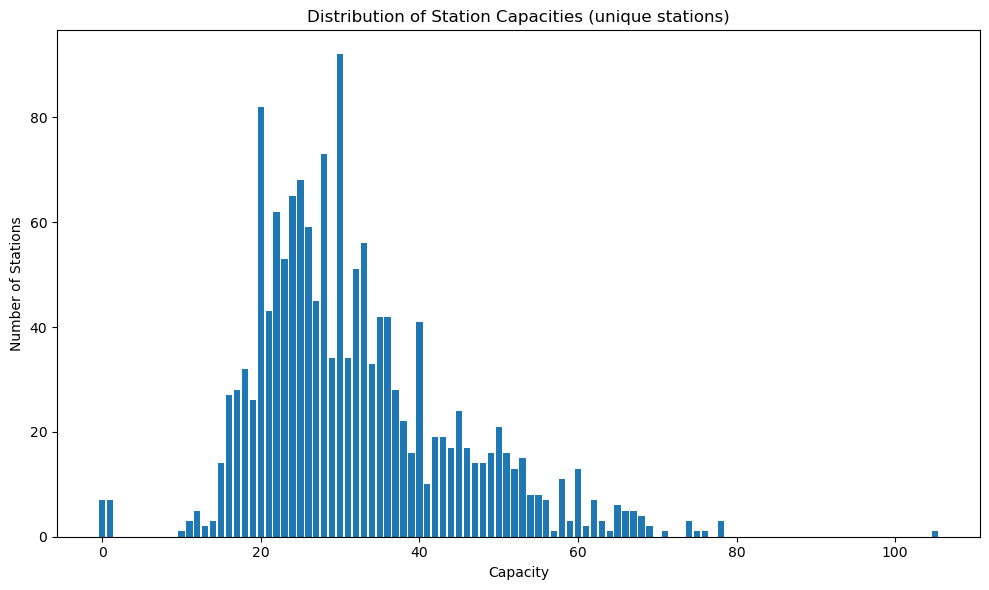

In [21]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


# REMOVE THE ONES WITH VERY LOW CAPACITY NUMBER

In [22]:
bad_capacity_stations = station_capacity[
    station_capacity["capacity"] <= 1
]["station_code"]

print("Stations to remove:", len(bad_capacity_stations))

Stations to remove: 14


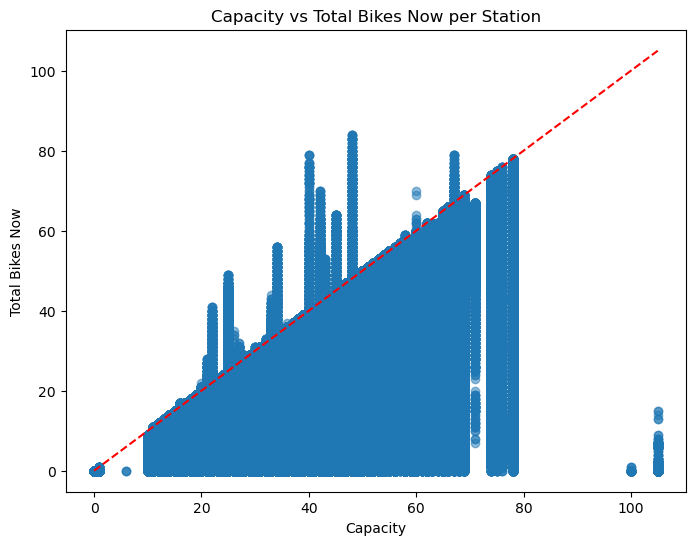

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station")
plt.show()

# REMOVE BAD CAPACITY STATIONS

In [24]:
# ~ means not in pandas
df = df[~df["station_code"].isin(bad_capacity_stations)]

# RECALCULATE AND PLOT AFTER REMOVING

Total stations: 1571
Sum of num_stations: 1493
Stations with no valid capacity:  78


,capacity,num_stations
0,10.0,1
1,11.0,3
2,12.0,5
3,13.0,2
4,14.0,3
...,...,...
61,74.0,3
62,75.0,1
63,76.0,1
64,78.0,3


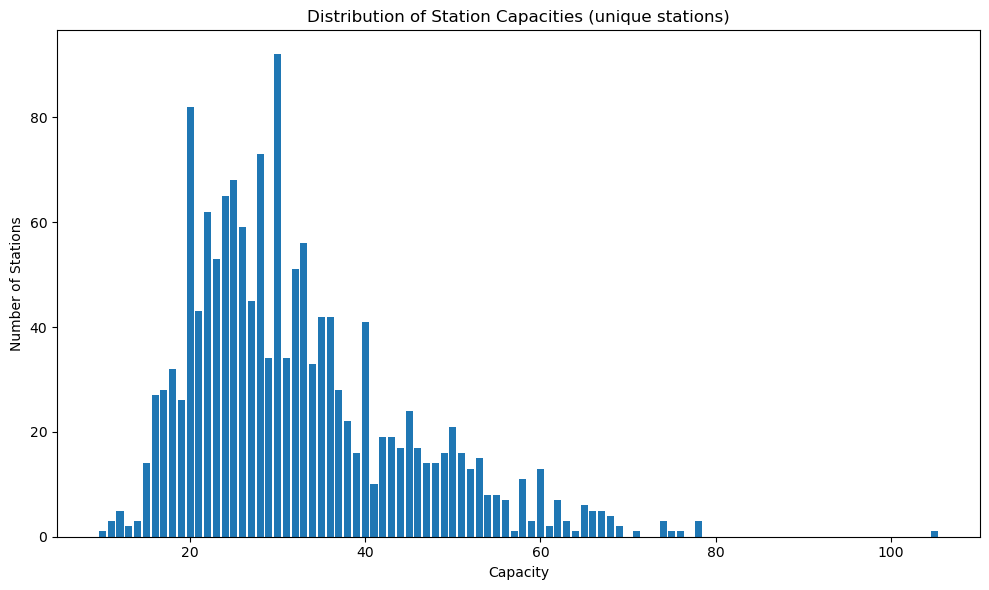

In [25]:
# Only one row per station_code to get unique capacities
station_capacity = (
    df.groupby("station_code")["capacity"]
      .max()
      .reset_index()
)

# Count how many stations have each capacity
capacity_counts = (
    station_capacity["capacity"]
    .value_counts()
    .sort_index()
    .reset_index()
)

capacity_counts.columns = ["capacity", "num_stations"]

print(f"Total stations: {station_capacity.shape[0]}")
print(f"Sum of num_stations:", capacity_counts["num_stations"].sum())
print(f"Stations with no valid capacity: ", (station_capacity.shape[0] - capacity_counts["num_stations"].sum()))


display(capacity_counts)


# Plot
plt.figure(figsize=(10,6))
plt.bar(capacity_counts["capacity"], capacity_counts["num_stations"])
plt.xlabel("Capacity")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station Capacities (unique stations)")
plt.tight_layout()
plt.show()


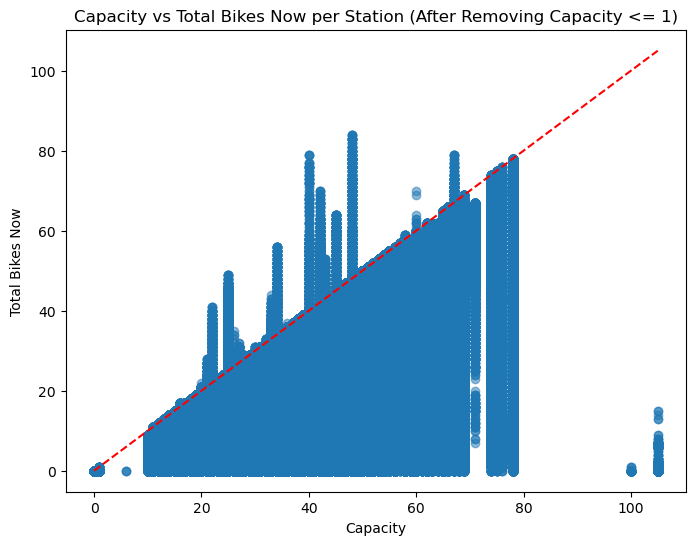

In [26]:
plt.figure(figsize=(8,6))
plt.scatter(df["capacity"], df["total_bikes_now"], alpha=0.5)
plt.plot([0, df["capacity"].max()], [0, df["capacity"].max()], color="red", linestyle="--")
plt.xlabel("Capacity")
plt.ylabel("Total Bikes Now")
plt.title("Capacity vs Total Bikes Now per Station (After Removing Capacity <= 1)")
plt.show()

# No change = normal because they do not exist here at all as they were broken

# CHECK THE STATIONS WITH DOTS ABOVE THE RED LINE(THEY HAVE MORE BIKES THAN CAPACITY)

In [27]:
suspicious = df[df["total_bikes_now"] > df["capacity"]]
print("Number of suspicious stations:", len(suspicious))
display(suspicious[["station_code", "capacity", "total_bikes_now", "total_bikes_taken"]])


Number of suspicious stations: 11788


,station_code,capacity,total_bikes_now,total_bikes_taken
683,15039,27.0,28.0,0.0
1439,42004,25.0,37.0,0.0
1488,21302,25.0,30.0,0.0
2171,15039,27.0,28.0,0.0
2933,42004,25.0,37.0,0.0
...,...,...,...,...
6068025,21302,25.0,39.0,1.0
6068031,12105,33.0,34.0,3.0
6068032,15056,22.0,23.0,2.0
6069521,21302,25.0,39.0,1.0


# CHECK THE PERCENTAGE OF IT TO NOT WRONGFULLY PURGE THE STATION WITH SMALL ERRORS

In [28]:
df["is_suspicious"] = df["total_bikes_now"] > df["capacity"]

station_stats = (
    df.groupby("station_code")
      .agg(
          total_rows=("station_code", "size"),
          suspicious_rows=("is_suspicious", "sum")
      )
)

station_stats["suspicious_ratio"] = (
    station_stats["suspicious_rows"] / station_stats["total_rows"]
)


station_stats_sorted = station_stats.sort_values("suspicious_ratio", ascending=False)
station_stats_nonzero = station_stats_sorted[station_stats_sorted["suspicious_ratio"] > 0]

DROP_THRESHOLD = 0.10

# Keep only stations with at least one suspicious row
stations_to_drop = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] >= DROP_THRESHOLD]
stations_to_rrow = station_stats_nonzero.loc[station_stats_sorted["suspicious_ratio"] < DROP_THRESHOLD]

print("Stations to drop:", len(stations_to_drop))
print("Stations to remove_rows:", len(stations_to_rrow))

display(station_stats_nonzero)

Stations to drop: 9
Stations to remove_rows: 22


,total_rows,suspicious_rows,suspicious_ratio
station_code,,,
21302,3970,2319,0.584131
42004,4014,2165,0.539362
13123,4014,1713,0.426756
15056,2543,746,0.293354
12105,2579,569,0.220628
12127,3464,760,0.219400
21021,4014,743,0.185102
33019,3985,661,0.165872
15058,3991,601,0.150589


# SAVE VERY SUSPICIOUS TO A FILE

In [47]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/suspicious_stations.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Suspicious stations saved: {len(station_stats_nonzero)}")
print(f"Saved: {broken_station_path}")

Suspicious stations saved: 31
Saved: ..\data\deleted_stations/suspicious_stations.csv


In [48]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/bad_stations1.csv"
stats = df[df["station_code"].isin(station_stats_nonzero)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)
station_stats_full = station_stats_nonzero.join(stats)


with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "total_rows", "suspicious_rows", "suspicious_ratio",
        "mean_total_bikes_now", "std_total_bikes_now", "min_total_bikes_now",
        "max_total_bikes_now", "median_total_bikes_now"
    ])
    for station, row in station_stats_full.iterrows():
        writer.writerow([
            station,
            row["total_rows"],
            row["suspicious_rows"],
            row["suspicious_ratio"],
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(stations_to_drop)}")
print(f"Saved: {broken_station_path}")

Broken stations saved: 9
Saved: ..\data\deleted_stations/bad_stations1.csv


# DROP THE VERY SUSPICIOUS STATIONS

In [49]:
df = df[~df["station_code"].isin(stations_to_drop)]

# REMOVE ROWS FOR STATIONS WITH MISTAKES

In [50]:
mask = (df["total_bikes_now"] > df["capacity"])
df = df[~mask]

In [51]:
TOTAL_REAL_ROWS_AT_START = df.shape[0]
TOTAL_REAL_STATIONS_AT_START = df["station_code"].nunique()
print(f"{TOTAL_REAL_ROWS_AT_START=}")
print(f"{TOTAL_REAL_STATIONS_AT_START=}")

TOTAL_REAL_ROWS_AT_START=5936004
TOTAL_REAL_STATIONS_AT_START=1493


# CHECK

In [52]:
print_df(df)
print_missing(df)

Dataframe analysis
-----------------------
Shape: 
rows:     5936004
features: 24
Dataframe size: 4876097857 bytes (4650.21 MB)
-----------------------
Percentage of rows removed: 2.21%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


station_name          object
station_code           int64
ebike                 object
mechanical            object
latitude             float64
longitude            float64
duedate               object
total_bikes_now      float64
total_bikes_taken    float64
capacity             float64
is_renting            object
is_installed          object
commune_name          object
is_returning          object
postal_code           object
timestamp             object
weather_interval      object
temperature          float64
is_day               float64
wind_speed           float64
wind_direction       float64
weather_code         float64
source_file           object
is_suspicious           bool
dtype: object

-----------------------


,station_code,latitude,longitude,total_bikes_now,total_bikes_taken,capacity,temperature,is_day,wind_speed,wind_direction,weather_code
count,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.933943e+06,5.933943e+06,5.933943e+06,5.933943e+06,5.933943e+06
mean,1.901205e+04,4.885787e+01,2.341723e+00,1.254274e+01,1.859498e+01,3.210310e+01,1.164738e+01,3.917129e-01,9.494260e+00,1.936668e+02,1.507936e+01
std,1.229355e+04,3.216351e-02,5.848255e-02,1.097444e+01,1.233095e+01,1.236939e+01,4.810724e+01,7.153235e-01,4.260006e+00,6.598277e+01,2.595037e+01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.103800e+04,4.883683e+01,2.302549e+00,4.000000e+00,1.000000e+01,2.300000e+01,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700700e+04,4.885816e+01,2.343996e+00,1.000000e+01,1.700000e+01,3.000000e+01,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230300e+04,4.887941e+01,2.379654e+00,1.800000e+01,2.600000e+01,3.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,1.000000e+02,1.050000e+02,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.150000e+02


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,2061,0
source_file,2061,0
temperature,2061,0
weather_code,2061,0
weather_interval,2061,0
wind_direction,2061,0
wind_speed,2061,0
capacity,0,0
commune_name,0,0
duedate,0,0


-----------------------


# DROP INVALID ROWS(DOESNT CONTAIN THE DATA FOR TOTAL_BIKES_NOW)

In [53]:
essential_data = [
    "station_name", 
    "station_code", 
    "postal_code", #
    "capacity", 
    "total_bikes_now", 
    "total_bikes_taken", 
    "timestamp"
]

df = df.dropna(subset=essential_data)

# RECHECK

In [54]:
print_missing(df)

Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
is_day,2061,0
source_file,2061,0
temperature,2061,0
weather_code,2061,0
weather_interval,2061,0
wind_direction,2061,0
wind_speed,2061,0
capacity,0,0
commune_name,0,0
duedate,0,0


-----------------------


# KEEPING THE USABLE COLUMNS

In [55]:
# Keep only useful columns
keep_cols = [
    "station_code",
    "latitude",
    "longitude",
    "capacity",
    "total_bikes_now",
    "total_bikes_taken",
    "timestamp",
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

df_cleaned = df[keep_cols].copy(deep=True)

print("Initial shape:", df_cleaned.shape)
print_df(df_cleaned)

Initial shape: (5936004, 12)
Dataframe analysis
-----------------------
Shape: 
rows:     5936004
features: 12
Dataframe size: 1003474266 bytes (956.99 MB)
-----------------------
Percentage of rows removed: 2.21%
Percentage of stations removed: 5.80%
Percentage of real rows removed: 0.00%
Percentage of real stations removed: 0.00%
-----------------------


station_code           int64
latitude             float64
longitude            float64
capacity             float64
total_bikes_now      float64
total_bikes_taken    float64
timestamp             object
temperature          float64
wind_speed           float64
wind_direction       float64
weather_code         float64
is_day               float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day
count,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.936004e+06,5.933943e+06,5.933943e+06,5.933943e+06,5.933943e+06,5.933943e+06
mean,1.901205e+04,4.885787e+01,2.341723e+00,3.210310e+01,1.254274e+01,1.859498e+01,1.164738e+01,9.494260e+00,1.936668e+02,1.507936e+01,3.917129e-01
std,1.229355e+04,3.216351e-02,5.848255e-02,1.236939e+01,1.097444e+01,1.233095e+01,4.810724e+01,4.260006e+00,6.598277e+01,2.595037e+01,7.153235e-01
min,1.001000e+03,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00,-7.000000e-01
25%,1.103800e+04,4.883683e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00
50%,1.700700e+04,4.885816e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,9.000000e+02,2.850000e+01,3.600000e+02,3.150000e+02,1.510000e+01


# WEATHER TIME HANDLING

In [56]:
df_cleaned["timestamp"] = pd.to_datetime(df_cleaned["timestamp"], errors="coerce")

# Drop rows without time
df_cleaned = df_cleaned.dropna(subset=["timestamp"])

# Time features
df_cleaned["hour"] = df_cleaned["timestamp"].dt.hour
df_cleaned["day_of_week"] = df_cleaned["timestamp"].dt.dayofweek
df_cleaned["is_weekend"] = (df_cleaned["day_of_week"] >= 5).astype(int)

# Cyclical encoding
df_cleaned["sin_hour"] = np.sin(2 * np.pi * df_cleaned["hour"] / 24)
df_cleaned["cos_hour"] = np.cos(2 * np.pi * df_cleaned["hour"] / 24)

In [57]:
print_df(df_cleaned)

Dataframe analysis
-----------------------
Shape: 
rows:     5916698
features: 17
Dataframe size: 804670928 bytes (767.39 MB)
-----------------------
Percentage of rows removed: 2.53%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.33%
Percentage of real stations removed: 0.20%
-----------------------


station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int32
day_of_week                   int32
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5916698,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06
mean,1.901189e+04,4.885787e+01,2.341722e+00,3.210311e+01,1.254384e+01,1.859394e+01,2025-11-28 14:59:48.407098880,9.058162e+00,9.520524e+00,1.942068e+02,1.463765e+01,3.644176e-01,1.142497e+01,2.985656e+00,2.843542e-01,1.086928e-02,3.065914e-03
min,1.001000e+03,4.875740e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883683e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-16 05:30:00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700700e+04,4.885816e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-11-28 11:15:00,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-11 01:15:00,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229343e+04,3.216232e-02,5.848242e-02,1.236937e+01,1.097371e+01,1.233079e+01,NaN,3.769072e+00,4.238216e+00,6.531484e+01,2.447591e+01,4.812665e-01,6.927292e+00,2.003798e+00,4.511063e-01,7.073176e-01,7.068058e-01


# CHANGE FEATURE DATA TYPES FOR MEMORY OPTIMISATION

In [58]:
"""
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "uint8",
    "total_bikes_now": "uint8",
    "total_bikes_taken": "uint8",
    "temperature": "float16",
    "wind_speed": "float16",
    "wind_direction": "float16",
    "weather_code": "uint8",
    "is_day": "uint8",
    "hour": "uint8",
    "day_of_week": "uint8",
    "is_weekend": "uint8",
    "sin_hour": "float32",
    "cos_hour": "float32"
})
"""
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "int64",
    "total_bikes_now": "int64",
    "total_bikes_taken": "int64",
    "temperature": "float64",
    "wind_speed": "float64",
    "wind_direction": "float64",
    "weather_code": "int64",
    "is_day": "int64",
    "hour": "int64",
    "day_of_week": "int64",
    "is_weekend": "int64",
    "sin_hour": "float64",
    "cos_hour": "float64"
})

print_df(df_cleaned)
df_cleaned.head()

Dataframe analysis
-----------------------
Shape: 
rows:     5916698
features: 17
Dataframe size: 828337720 bytes (789.96 MB)
-----------------------
Percentage of rows removed: 2.53%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.33%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now               int64
total_bikes_taken             int64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5916698,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06,5.916698e+06
mean,1.901189e+04,4.885787e+01,2.341722e+00,3.210311e+01,1.254384e+01,1.859394e+01,2025-11-28 14:59:48.407098880,9.058162e+00,9.520524e+00,1.942068e+02,1.463765e+01,3.644176e-01,1.142497e+01,2.985656e+00,2.843542e-01,1.086928e-02,3.065914e-03
min,1.001000e+03,4.875740e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883683e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,2025-11-16 05:30:00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700700e+04,4.885816e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-11-28 11:15:00,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-11 01:15:00,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229343e+04,3.216232e-02,5.848242e-02,1.236937e+01,1.097371e+01,1.233079e+01,NaN,3.769072e+00,4.238216e+00,6.531484e+01,2.447591e+01,4.812665e-01,6.927292e+00,2.003798e+00,4.511063e-01,7.073176e-01,7.068058e-01


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
0,14111,48.837526,2.336035,25,2,22,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
1,32017,48.936269,2.358867,22,6,16,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
2,11104,48.855908,2.392571,20,2,18,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
3,5110,48.843893,2.351966,23,7,15,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5
4,6108,48.847082,2.321375,17,4,11,2025-11-04 04:00:00,10.1,9.5,217.0,3,0,4,1,0,0.866025,0.5


# DETECTING THE DUPLICATE ROWS(MULTIPLE ROWS FOR THE SAME (STATION, TIMESTAMP) COUPLES)

In [59]:
dup_mask = df_cleaned.duplicated(
    subset=["station_code", "timestamp"],
    keep=False
)

print(f"Duplicate rows: {dup_mask.sum()}")

display(
    df_cleaned.loc[dup_mask]
    .groupby(["station_code", "timestamp"])
    .size()
    .rename("dup_count")
    .sort_values(ascending=False)
    .head(10)
)


Duplicate rows: 19505


station_code  timestamp          
13101         2025-11-07 04:00:00    4
15021         2025-11-07 04:00:00    4
15018         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
25010         2025-11-07 04:00:00    4
              2025-11-07 03:45:00    4
15019         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
15020         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
Name: dup_count, dtype: int64

# SET THE AGGREGATION RULES

In [60]:
agg_rules = {
    "latitude": "first",
    "longitude": "first",
    "capacity": "first",
    "total_bikes_now": "mean",
    "total_bikes_taken": "mean",
    "temperature": "mean",
    "wind_speed": "mean",
    "wind_direction": "mean",
    "weather_code": "first", # should be mean
    "is_day": "first",
    "hour": "first",
    "day_of_week": "first",
    "is_weekend": "first",
    "sin_hour": "first",
    "cos_hour": "first",
}

# APPLY AGGREGATION RULES

In [61]:
before = len(df_cleaned)

df_cleaned = (
    df_cleaned
    .groupby(["station_code", "timestamp"], as_index=False)
    .agg(agg_rules)
)

after = len(df_cleaned)

print("Rows before:", before)
print("Rows after :", after)
print("Duplicates removed:", before - after)


Rows before: 5916698
Rows after : 5903989
Duplicates removed: 12709


# CHECK IF THERE ARE STILL DUPLICATES

In [62]:
assert not df_cleaned.duplicated(
    ["station_code", "timestamp"]
).any()
# No error means no duplicates

# HISTOGRAM OF ROWS

In [63]:
df_counts = df_cleaned["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)

      station_code  count
0            42304   3989
1            32022   3989
2            41204   3989
3            41202   3989
4            32605   3989
...            ...    ...
1485         42004   1837
1486         15056   1781
1487         22209   1665
1488         21302   1638
1489         35010      3

[1490 rows x 2 columns]


count
3         1
1638      1
1665      1
1781      1
1837      1
1991      1
2278      1
2398      1
2494      1
2676      1
2859      1
2863      1
3177      1
3184      1
3243      1
3302      1
3319      1
3364      1
3450      1
3478      1
3482      1
3584      1
3646      1
3711      1
3766      1
3864      1
3907      1
3917      1
3953      1
3954      1
3967      1
3969      2
3972      1
3973      1
3974      7
3975     11
3976     46
3977      2
3978     35
3979     36
3980    181
3981     69
3982    154
3983    185
3984    282
3985    124
3986    177
3987     89
3988     30
3989     27
Name: count, dtype: int64


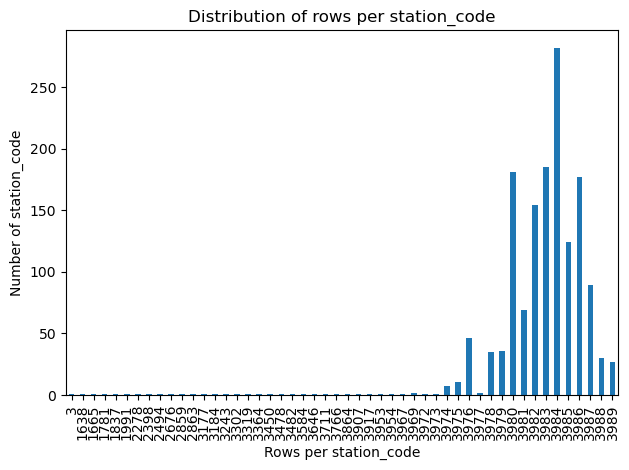

In [64]:
counts = df_cleaned["station_code"].value_counts()   # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()

# MAKE THE MAP BEFORE DELETING STATIONS

In [65]:
def save_unique_stations_map_html(
    df,
    out_html="idf_stations",
    station_col="station_code",
    lat_col="latitude",
    lon_col="longitude",
    radius=0.01,               
    color="red",
    fill_opacity=0.8,
    zoom_start=10,
    tiles="CartoDB positronNoLabels",
):
    # Keep only needed cols, drop missing coords
    d = df[[station_col, lat_col, lon_col]].dropna(subset=[lat_col, lon_col])

    # Keep one row per station (huge speedup vs millions of rows)
    d = d.drop_duplicates(subset=[station_col], keep="first")

    # Ensure numeric
    d[lat_col] = d[lat_col].astype(float)
    d[lon_col] = d[lon_col].astype(float)

    # Center map
    center_lat = float(d[lat_col].mean())
    center_lon = float(d[lon_col].mean())

    # Minimal basemap
    m = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles=tiles)

    # Plot points
    for code, la, lo in zip(d[station_col], d[lat_col], d[lon_col]):
        folium.CircleMarker(
            location=[la, lo],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            tooltip=str(code),
        ).add_to(m)
    out_path = f"{MAP_FOLDER}/{out_html}.html"
    m.save(out_path)
    return out_path, len(d)


In [66]:
html_path, n = save_unique_stations_map_html(df_cleaned, out_html="idf_stations_before", radius=0.01)
print("Saved:", html_path, "| stations mapped:", n)

Saved: ..\data\maps/idf_stations_before.html | stations mapped: 1490


# DETECT BROKEN STATIONS

In [67]:
MIN_ROWS = counts.quantile(0.05)   # up to ~5% of the stations at the bottom can be deleted

cols = ["total_bikes_now", "total_bikes_taken"]

station_stats = (
    df_cleaned
    .groupby("station_code")[cols]
    .agg(["count", "mean", "std"])
)

# This ignores the NaN values for total_bikes_now
rule_few_rows = station_stats[("total_bikes_now", "count")] < MIN_ROWS

rule_now_bad = (
    station_stats[("total_bikes_now", "std")].isna() |
    (station_stats[("total_bikes_now", "std")] < 0.1) |
    (station_stats[("total_bikes_now", "mean")] < 0.5)
)

rule_taken_bad = (
    station_stats[("total_bikes_taken", "std")].isna() |
    (station_stats[("total_bikes_taken", "std")] < 0.1) |
    (station_stats[("total_bikes_taken", "mean")] < 0.5)
)

bad_stations = station_stats[
    rule_few_rows | rule_now_bad | rule_taken_bad
].index

print(rule_few_rows.sum(), "stations removed by row count")
print(rule_now_bad.sum(), "stations removed by bikes_now stats")
print(rule_taken_bad.sum(), "stations removed by bikes_taken stats")
print(f"Stations to remove: {len(bad_stations)}")

good_stations = df_cleaned["station_code"].unique()
good_stations = [s for s in good_stations if s not in bad_stations]

print(f"Stations to keep: {len(good_stations)}")


53 stations removed by row count
12 stations removed by bikes_now stats
7 stations removed by bikes_taken stats
Stations to remove: 64
Stations to keep: 1426


# REMOVE THE BROKEN STATIONS

In [68]:
print_df(df_cleaned)

df_kept = df_cleaned[df_cleaned["station_code"].isin(good_stations)].copy()

print_df(df_kept)

Dataframe analysis
-----------------------
Shape: 
rows:     5903989
features: 17
Dataframe size: 779326680 bytes (743.22 MB)
-----------------------
Percentage of rows removed: 2.74%
Percentage of stations removed: 5.99%
Percentage of real rows removed: 0.54%
Percentage of real stations removed: 0.20%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.903989e+06,5903989,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06,5.903989e+06
mean,1.901126e+04,2025-11-28 16:03:36.708940288,4.885787e+01,2.341721e+00,3.210343e+01,1.254239e+01,1.859550e+01,9.054986e+00,9.527455e+00,1.942910e+02,1.466404e+01,3.651265e-01,1.144025e+01,2.984297e+00,2.849663e-01,9.291059e-03,1.948707e-03
min,1.001000e+03,2025-11-04 04:00:00,4.875740e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,2025-11-16 07:00:00,4.883683e+01,2.302549e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700700e+04,2025-11-28 12:45:00,4.885816e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230300e+04,2025-12-11 01:45:00,4.887941e+01,2.379654e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.140000e+01,1.230000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,1.050000e+02,7.800000e+01,1.000000e+02,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.229329e+04,NaN,3.216170e-02,5.848111e-02,1.236947e+01,1.097410e+01,1.233025e+01,3.772355e+00,4.239707e+00,6.535107e+01,2.449559e+01,4.814657e-01,6.925561e+00,2.005236e+00,4.513984e-01,7.070974e-01,7.070525e-01


Dataframe analysis
-----------------------
Shape: 
rows:     5680006
features: 17
Dataframe size: 795200840 bytes (758.36 MB)
-----------------------
Percentage of rows removed: 6.43%
Percentage of stations removed: 10.03%
Percentage of real rows removed: 4.31%
Percentage of real stations removed: 4.49%
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      int64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                  int64
is_day                        int64
hour                          int64
day_of_week                   int64
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.680006e+06,5680006,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06,5.680006e+06
mean,1.913613e+04,2025-11-28 16:00:58.688336640,4.885764e+01,2.340918e+00,3.217563e+01,1.267016e+01,1.852994e+01,9.058691e+00,9.514783e+00,1.942983e+02,1.466097e+01,3.654362e-01,1.144043e+01,2.983480e+00,2.847712e-01,9.246207e-03,1.443043e-03
min,1.001000e+03,2025-11-04 04:00:00,4.875740e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103900e+04,2025-11-16 07:00:00,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,1.000000e+01,6.800000e+00,6.500000e+00,1.590000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700700e+04,2025-11-28 12:45:00,4.885799e+01,2.343335e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.200000e+00,9.300000e+00,1.840000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.240800e+04,2025-12-11 01:30:00,4.887949e+01,2.378796e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.241283e+04,NaN,3.235522e-02,5.860670e-02,1.222002e+01,1.097865e+01,1.216768e+01,3.772538e+00,4.236680e+00,6.534877e+01,2.449336e+01,4.815523e-01,6.923652e+00,2.005051e+00,4.513054e-01,7.070220e-01,7.071298e-01


# BUILD THE FULL BUT EMPTY(FOR NOW) DATAFRAME

In [69]:
# Min / max timestamp per station
station_ranges = (
    df_kept
    .groupby("station_code")["timestamp"]
    .agg(["min", "max"])
)

dfs = []

for station, (start, end) in station_ranges.iterrows():
    full_index = pd.date_range(start, end, freq="15min")

    full_df = pd.DataFrame({
        "station_code": station,
        "timestamp": full_index
    })

    merged = full_df.merge(
        df_kept[df_kept["station_code"] == station],
        on=["station_code", "timestamp"],
        how="left"
    )

    dfs.append(merged)

df_full = pd.concat(dfs, ignore_index=True)

print("Rows after full timeline:", len(df_full))
print("Added rows:", len(df_full) - len(df_kept))


Rows after full timeline: 6756314
Added rows: 1076308


# DETECT MISSING ROWS

In [70]:
missing_rows = df_full[df_full["total_bikes_now"].isna()]

missing_per_station = (
    missing_rows
    .groupby("station_code")
    .size()
    .sort_values(ascending=False)
)

print("Stations with most missing rows:")
print(missing_per_station.head(10))

Stations with most missing rows:
station_code
23802    762
20140    762
20202    762
12156    762
19037    762
20203    762
20029    762
20027    762
12129    762
20023    762
dtype: int64


# FILL STATIC COLUMNS

In [71]:
static_cols = ["latitude", "longitude", "capacity"] # Will be the same for its own station

df_full[static_cols] = (
    df_full
    .groupby("station_code")[static_cols]
    .transform("first")
)

# FILL WEATHER DATA WITH MEAN

In [72]:
weather_cols = [
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

for col in weather_cols:
    df_full[col] = (
        df_full
        .groupby("station_code")[col]
        .transform(lambda x: x.fillna(x.mean()))
    )

# FILL BIKE DATA WITH INTERPOLATION

In [73]:
bike_cols = ["total_bikes_now", "total_bikes_taken"]

# Sort first
df_full = df_full.sort_values(["station_code", "timestamp"])

# Interpolate per station using timestamp as index
def interpolate_bikes(group):
    group = group.set_index("timestamp")  # DatetimeIndex required
    group[bike_cols] = group[bike_cols].interpolate(method="time")
    return group.reset_index()

df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)

# Fill edges
df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")


C:\Users\emirh\AppData\Local\Temp\ipykernel_134720\2741860525.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)
C:\Users\emirh\AppData\Local\Temp\ipykernel_134720\2741860525.py:15: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")


# FILL THE REST OF THE TIME DATA

In [74]:
df_full["hour"] = df_full["timestamp"].dt.hour.astype("uint8")
df_full["day_of_week"] = df_full["timestamp"].dt.dayofweek.astype("uint8")
df_full["is_weekend"] = (df_full["day_of_week"] >= 5).astype("uint8")
df_full["sin_hour"] = np.sin(2 * np.pi * df_full["hour"] / 24).astype("float32")
df_full["cos_hour"] = np.cos(2 * np.pi * df_full["hour"] / 24).astype("float32")

# CHECK

In [75]:
print("Remaining NaNs per column:")
print(df_full.isna().sum())

print("Final rows:", len(df_full))
print("Final stations:", df_full["station_code"].nunique())

Remaining NaNs per column:
timestamp            0
station_code         0
latitude             0
longitude            0
capacity             0
total_bikes_now      0
total_bikes_taken    0
temperature          0
wind_speed           0
wind_direction       0
weather_code         0
is_day               0
hour                 0
day_of_week          0
is_weekend           0
sin_hour             0
cos_hour             0
dtype: int64
Final rows: 6756314
Final stations: 1426


# MAKE THE MAP AFTER DELETING/REFILLING

In [76]:
html_path, n = save_unique_stations_map_html(df_full, radius=0.01, out_html="idf_stations_removed_refilled")
print("Saved:", html_path, "| stations mapped:", n)

Saved: ..\data\maps/idf_stations_removed_refilled.html | stations mapped: 1426


# SAVE THE BROKEN STATIONS IN A FILE

In [77]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/broken_stations2.csv"
stats = df_cleaned[df_cleaned["station_code"].isin(bad_stations)].groupby("station_code")["total_bikes_now"].agg(
    ["mean", "std", "min", "max", "median"]
)

with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "mean_total_bikes_now", "std_total_bikes_now"])
    for station, row in stats.iterrows():
        writer.writerow([
            station,
            row["mean"],
            row["std"],
            row["min"],
            row["max"],
            row["median"]
        ])

print(f"Broken stations saved: {len(bad_stations)}")
print(f"Saved: {broken_station_path}")

Broken stations saved: 64
Saved: ..\data\deleted_stations/broken_stations2.csv


# CHECK

In [78]:
print(df_full.isna().sum().sort_values(ascending=False))

timestamp            0
wind_direction       0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_speed           0
station_code         0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
cos_hour             0
dtype: int64


# DETAILS

In [79]:
print_df(df_full)

Dataframe analysis
-----------------------
Shape: 
rows:     6756314
features: 17
Dataframe size: 722925730 bytes (689.44 MB)
-----------------------
Percentage of rows removed: -11.30%
Percentage of stations removed: 10.03%
Percentage of real rows removed: -13.82%
Percentage of real stations removed: 4.49%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,6756314,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06,6.756314e+06
mean,2025-11-28 20:07:53.342432768,1.913597e+04,4.885764e+01,2.340920e+00,3.209192e+01,1.266654e+01,1.853420e+01,9.058651e+00,9.514840e+00,1.942983e+02,1.466101e+01,3.654364e-01,1.147328e+01,2.985670e+00,2.836671e-01,5.165605e-03,-2.571193e-03
min,2025-11-04 04:00:00,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,2025-11-16 12:00:00,1.103900e+04,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,9.500000e+00,7.200000e+00,7.100000e+00,1.630000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,2025-11-28 20:15:00,1.700800e+04,4.885783e+01,2.343335e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.120996e+00,9.328840e+00,1.922556e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2025-12-11 04:15:00,2.240800e+04,4.887949e+01,2.378796e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.090000e+01,1.160000e+01,2.160000e+02,1.465930e+01,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,NaN,1.241258e+04,3.235308e-02,5.860902e-02,1.232118e+01,1.097167e+01,1.215770e+01,3.459740e+00,3.889373e+00,5.992255e+01,2.245822e+01,4.415328e-01,6.907651e+00,1.999949e+00,4.507772e-01,7.098426e-01,7.087350e-01


In [80]:
print(df_full.isna().sum().sort_values(ascending=False))

timestamp            0
wind_direction       0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_speed           0
station_code         0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
cos_hour             0
dtype: int64


# ADD BIKE LAG

In [81]:
df_full = df_full.sort_values(["station_code", "timestamp"])
df_full["total_bikes_lag1"] = df_full.groupby("station_code")["total_bikes_now"].shift(1)
df_full["total_bikes_lag2"] = df_full.groupby("station_code")["total_bikes_now"].shift(2)
df_full = df_full.dropna(subset=["total_bikes_lag1", "total_bikes_lag2"]).copy()

# SPLIT THE DATASET

In [82]:
df_full["split"] = None
for station_code, df_station in df_full.groupby("station_code"):
    n = len(df_station)
    train_end = int(0.7 * n)
    val_end = int(0.85 * n)

    # Get original indices
    idx = df_station.index
    df_full.loc[idx[:train_end], "split"] = 0 # "train"
    df_full.loc[idx[train_end:val_end], "split"] = 1 # "val"
    df_full.loc[idx[val_end:], "split"] = 2 # "test"

# LAST CHECK

In [83]:
print_df(df_full)
print_missing(df_full)

Dataframe analysis
-----------------------
Shape: 
rows:     6753462
features: 20
Dataframe size: 1398360802 bytes (1333.58 MB)
-----------------------
Percentage of rows removed: -11.25%
Percentage of stations removed: 10.03%
Percentage of real rows removed: -13.77%
Percentage of real stations removed: 4.49%
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
total_bikes_lag1            float64
total_bikes_lag2            float64
split                        object
dtype: object

-----------------------


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2
count,6753462,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06,6.753462e+06
mean,2025-11-28 20:22:53.342425856,1.913597e+04,4.885764e+01,2.340920e+00,3.209192e+01,1.266612e+01,1.853454e+01,9.058437e+00,9.514858e+00,1.942935e+02,1.466354e+01,3.655155e-01,1.147643e+01,2.986508e+00,2.837869e-01,4.802063e-03,-2.783430e-03,1.266625e+01,1.266638e+01
min,2025-11-04 04:30:00,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00
25%,2025-11-16 12:30:00,1.103900e+04,4.883650e+01,2.302116e+00,2.300000e+01,4.000000e+00,9.500000e+00,7.200000e+00,7.100000e+00,1.630000e+02,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01,4.000000e+00,4.000000e+00
50%,2025-11-28 20:30:00,1.700800e+04,4.885783e+01,2.343335e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.120801e+00,9.328840e+00,1.922544e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16,1.000000e+01,1.000000e+01
75%,2025-12-11 04:30:00,2.240800e+04,4.887949e+01,2.378796e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.100000e+01,1.160000e+01,2.160000e+02,1.465930e+01,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01,1.800000e+01,1.800000e+01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.800000e+01,7.800000e+01,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.800000e+01,7.800000e+01
std,NaN,1.241258e+04,3.235308e-02,5.860902e-02,1.232118e+01,1.097179e+01,1.215740e+01,3.460437e+00,3.890185e+00,5.993430e+01,2.246230e+01,4.415933e-01,6.907402e+00,1.999955e+00,4.508347e-01,7.097728e-01,7.088107e-01,1.097172e+01,1.097165e+01


Missing diagnostics
-----------------------

NaN / Inf per column:


,nan,inf
capacity,0,0
cos_hour,0,0
day_of_week,0,0
hour,0,0
is_day,0,0
is_weekend,0,0
latitude,0,0
longitude,0,0
sin_hour,0,0
split,0,0


-----------------------


# SAVE ONLY THE STATIONS AND THEIR COORDINATES

In [84]:
df_coordinates = df_full[["station_code", "longitude", "latitude"]]
df_coordinates = df_coordinates.drop_duplicates(subset=["station_code"], keep="first")
df_coordinates.to_csv(f"{COORDINATES_FOLDER}/station_coordinates.csv", index=False)
print(f"Stations coordinates saved to: {COORDINATES_FOLDER}/station_coordinates.csv")

# TODO: IF WE WANT TO MAKE A DATASET CONTAINING ONLY STATION INFO SUCH AS STATION NAME AND COMMUN NAME, WE HAVE TO CHANGE THE PART WHERE WE CHOOSE TO KEEP THE COLUMNS

Stations coordinates saved to: ..\data\station_coordinates/station_coordinates.csv


# LAST HEAD

In [85]:
display(df_full.head(10))

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour,total_bikes_lag1,total_bikes_lag2,split
2,2025-11-04 04:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.000000,8.000000,207.000000,3.000000,0.000000,4,1,0,0.866025,5.000000e-01,2.0,2.0,0
3,2025-11-04 04:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.200000,203.000000,3.000000,0.000000,4,1,0,0.866025,5.000000e-01,2.0,2.0,0
4,2025-11-04 05:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.094372,9.283279,192.757663,14.660302,0.365327,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
5,2025-11-04 05:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.100000,201.000000,3.000000,0.000000,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
6,2025-11-04 05:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.400000,200.000000,3.000000,0.000000,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
7,2025-11-04 05:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.100000,8.700000,197.000000,3.000000,0.000000,5,1,0,0.965926,2.588190e-01,2.0,2.0,0
8,2025-11-04 06:00:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.200000,8.700000,197.000000,2.000000,0.000000,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
9,2025-11-04 06:15:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.200000,8.700000,197.000000,2.000000,1.000000,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
10,2025-11-04 06:30:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.094372,9.283279,192.757663,14.660302,0.365327,6,1,0,1.000000,6.123234e-17,2.0,2.0,0
11,2025-11-04 06:45:00,1001,48.857059,2.341798,17.0,2.0,15.0,9.300000,8.600000,202.000000,2.000000,1.000000,6,1,0,1.000000,6.123234e-17,2.0,2.0,0


# SAVE THE FINAL CLEAN DATASET

In [86]:
df_full.to_csv(f"{DATASET_OUTPUT_FOLDER}/{FINAL_CSV_FILE_NAME}.csv", index=False)
print(f"Clean dataset saved: {FINAL_CSV_FILE_NAME}.csv")

Clean dataset saved: final_clean_split_data.csv
